### 01 — Dataset Exploration (BrainScan AI)
Goal
Inspect the raw MRI dataset, understand its folder structure, validate image readability, summarize labels/classes, visualize examples, and export a clean image manifest for Notebook 02.

Important assumptions: this notebook infers the classification label from the first directory beneath DATASET_ROOT (for example, train/glioma/image.jpg → glioma when CLASS_PARENT_LEVEL=1 relative to DATASET_ROOT). Set the configuration to match your actual extracted dataset. If your dataset uses a CSV annotation file or a YOLO bounding-box format, do not treat folder names as the full detection annotations; preserve and inspect those annotations separately.

Run from the project root or use .env paths. The notebook can also be configured manually below.

In [1]:
from pathlib import Path
import os
import random
import json
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, UnidentifiedImageError
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Project root: assumes this notebook is stored in <project>/notebooks/
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Override these paths if your extracted dataset is somewhere else.
DATASET_ROOT = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"

# For folders like data/raw/<class_name>/<image>.jpg use 1.
# For data/raw/train/<class_name>/<image>.jpg, set 2 if DATASET_ROOT is data/raw.
CLASS_PARENT_LEVEL = 1

SUPPORTED_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
MAX_EXAMPLES_PER_CLASS = 5

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Dataset root:", DATASET_ROOT)
print("Dataset root exists:", DATASET_ROOT.exists())
if not DATASET_ROOT.exists():
    raise FileNotFoundError(f"Dataset root not found: {DATASET_ROOT}. Update DATASET_ROOT.")


Project root: /home/moali/projects/brainscan_ai
Dataset root: /home/moali/projects/brainscan_ai/data/raw
Dataset root exists: True


### 2. Inspect the directory structure
This helps determine whether the dataset is organized by class folders, split folders, or another format before assigning labels.

In [2]:
def show_tree(root: Path, max_depth: int = 3, max_items_per_dir: int = 12):
    root = root.resolve()
    print(f"{root}/")
    for current, dirs, files in os.walk(root):
        current_path = Path(current)
        depth = len(current_path.relative_to(root).parts)
        if depth >= max_depth:
            dirs[:] = []
        indent = "  " * (depth + 1)
        for directory in sorted(dirs)[:max_items_per_dir]:
            print(f"{indent}{directory}/")
        for filename in sorted(files)[:max_items_per_dir]:
            print(f"{indent}{filename}")
        if len(files) > max_items_per_dir:
            print(f"{indent}... plus {len(files)-max_items_per_dir} more files")

show_tree(DATASET_ROOT)


/home/moali/projects/brainscan_ai/data/raw/
  glioma/
  meningioma/
  notumor/
  pituitary/
  .gitkeep
    Te-glTr_0000.jpg
    Te-glTr_0001.jpg
    Te-glTr_0002.jpg
    Te-glTr_0003.jpg
    Te-glTr_0004.jpg
    Te-glTr_0005.jpg
    Te-glTr_0006.jpg
    Te-glTr_0007.jpg
    Te-glTr_0008.jpg
    Te-glTr_0009.jpg
    Te-gl_0010.jpg
    Te-gl_0011.jpg
    ... plus 1609 more files
    Te-meTr_0000.jpg
    Te-meTr_0001.jpg
    Te-meTr_0002.jpg
    Te-meTr_0003.jpg
    Te-meTr_0004.jpg
    Te-meTr_0005.jpg
    Te-meTr_0006.jpg
    Te-meTr_0007.jpg
    Te-meTr_0008.jpg
    Te-meTr_0009.jpg
    Te-me_0010.jpg
    Te-me_0011.jpg
    ... plus 1633 more files
    Te-piTr_0000.jpg
    Te-piTr_0001.jpg
    Te-piTr_0002.jpg
    Te-piTr_0003.jpg
    Te-piTr_0004.jpg
    Te-piTr_0005.jpg
    Te-piTr_0006.jpg
    Te-piTr_0007.jpg
    Te-piTr_0008.jpg
    Te-piTr_0009.jpg
    Te-pi_0010.jpg
    Te-pi_0011.jpg
    ... plus 1745 more files
    Te-noTr_0000.jpg
    Te-noTr_0001.jpg
    Te-noTr_0002.jpg
   

### 3. Discover image files

In [3]:
image_paths = sorted(
    p for p in DATASET_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in SUPPORTED_EXTENSIONS
)

print(f"Images discovered: {len(image_paths):,}")
if not image_paths:
    raise ValueError(
        "No supported images found. Check DATASET_ROOT and SUPPORTED_EXTENSIONS. "
        "If the dataset is still archived, extract it first."
    )

print("Sample paths:")
for path in image_paths[:10]:
    print(" -", path.relative_to(DATASET_ROOT))


Images discovered: 7,023
Sample paths:
 - glioma/Te-glTr_0000.jpg
 - glioma/Te-glTr_0001.jpg
 - glioma/Te-glTr_0002.jpg
 - glioma/Te-glTr_0003.jpg
 - glioma/Te-glTr_0004.jpg
 - glioma/Te-glTr_0005.jpg
 - glioma/Te-glTr_0006.jpg
 - glioma/Te-glTr_0007.jpg
 - glioma/Te-glTr_0008.jpg
 - glioma/Te-glTr_0009.jpg


### 4. Infer labels from the folder structure
The default label is the directory CLASS_PARENT_LEVEL levels above the image file relative to DATASET_ROOT. Inspect the preview carefully. If folders represent train/validation/test rather than class names, change DATASET_ROOT to the directory that contains the class folders or customize the label logic.

In [4]:
def infer_label(image_path: Path, dataset_root: Path, class_parent_level: int = 1) -> str:
    relative = image_path.relative_to(dataset_root)
    # relative.parts[-1] is filename; parts[-2] is immediate parent folder.
    label_index = len(relative.parts) - 1 - class_parent_level
    if label_index < 0:
        return "__UNKNOWN__"
    return relative.parts[label_index]

records = []
for path in image_paths:
    records.append({
        "image_path": str(path.resolve()),
        "relative_path": str(path.relative_to(DATASET_ROOT)),
        "label": infer_label(path, DATASET_ROOT, CLASS_PARENT_LEVEL),
        "extension": path.suffix.lower(),
        "file_size_bytes": path.stat().st_size,
    })

manifest = pd.DataFrame(records)
display(manifest.head(10))
print("Inferred labels:", sorted(manifest["label"].unique()))

if (manifest["label"] == "__UNKNOWN__").any():
    print("WARNING: Some labels could not be inferred. Review folder depth and CLASS_PARENT_LEVEL.")


,image_path,relative_path,label,extension,file_size_bytes
0,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0000.jpg,glioma,.jpg,25826
1,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0001.jpg,glioma,.jpg,20982
2,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0002.jpg,glioma,.jpg,13285
3,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0003.jpg,glioma,.jpg,26137
4,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0004.jpg,glioma,.jpg,21709
5,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0005.jpg,glioma,.jpg,18238
6,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0006.jpg,glioma,.jpg,22264
7,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0007.jpg,glioma,.jpg,20559
8,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0008.jpg,glioma,.jpg,21709
9,/home/moali/projects/brainscan_ai/data/raw/gli...,glioma/Te-glTr_0009.jpg,glioma,.jpg,20819


Inferred labels: ['glioma', 'meningioma', 'notumor', 'pituitary']


### 5. Check duplicates and validate image readability
This checks duplicate paths and uses Pillow to verify that files can be opened. It does not determine whether two different files contain visually identical images.

In [5]:
duplicate_path_mask = manifest["image_path"].duplicated(keep=False)
print("Duplicate manifest paths:", int(duplicate_path_mask.sum()))
if duplicate_path_mask.any():
    display(manifest.loc[duplicate_path_mask].sort_values("image_path"))

valid_rows = []
invalid_rows = []
for row in manifest.to_dict("records"):
    path = Path(row["image_path"])
    try:
        with Image.open(path) as img:
            img.verify()
        # Re-open to read metadata after verify().
        with Image.open(path) as img:
            width, height = img.size
            mode = img.mode
        row["width"] = int(width)
        row["height"] = int(height)
        row["image_mode"] = mode
        row["is_valid"] = True
        valid_rows.append(row)
    except (OSError, UnidentifiedImageError, ValueError) as exc:
        row["is_valid"] = False
        row["validation_error"] = str(exc)
        invalid_rows.append(row)

valid_manifest = pd.DataFrame(valid_rows)
invalid_manifest = pd.DataFrame(invalid_rows)
print(f"Readable images: {len(valid_manifest):,}")
print(f"Invalid/unreadable images: {len(invalid_manifest):,}")
if not invalid_manifest.empty:
    display(invalid_manifest[["image_path", "label", "validation_error"]].head(30))


Duplicate manifest paths: 0
Readable images: 7,023
Invalid/unreadable images: 0


### 6. Class balance and summary statistics

,image_count,percentage
label,,
notumor,2000,28.48
pituitary,1757,25.02
meningioma,1645,23.42
glioma,1621,23.08


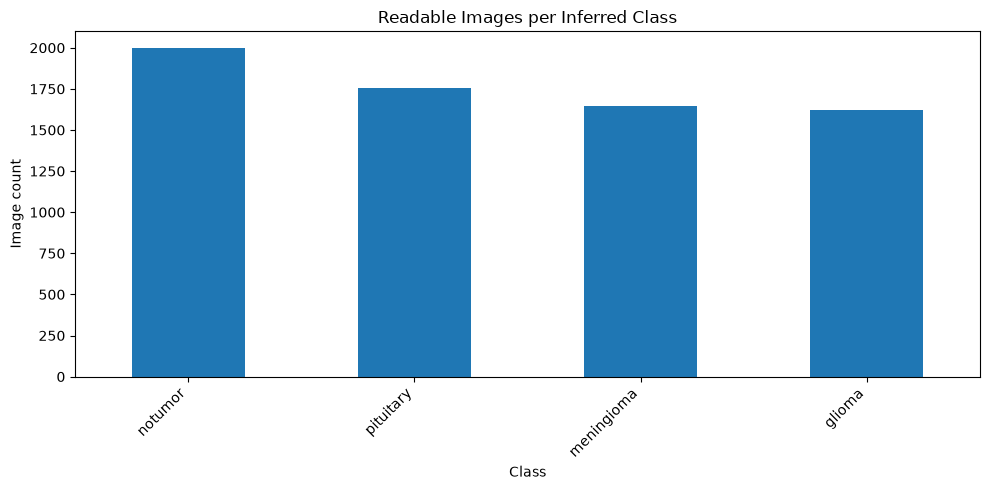

Total discovered: 7023
Valid images: 7023
Invalid images: 0
Number of classes: 4
Smallest class: 1621
Largest class: 2000


In [6]:
if valid_manifest.empty:
    raise ValueError("No readable images remain. Inspect invalid files and dataset paths.")

class_summary = (
    valid_manifest.groupby("label")
    .size()
    .rename("image_count")
    .to_frame()
)
class_summary["percentage"] = (class_summary["image_count"] / len(valid_manifest) * 100).round(2)
class_summary = class_summary.sort_values("image_count", ascending=False)
display(class_summary)

ax = class_summary["image_count"].plot(kind="bar", figsize=(10, 5), title="Readable Images per Inferred Class")
ax.set_xlabel("Class")
ax.set_ylabel("Image count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

print("Total discovered:", len(manifest))
print("Valid images:", len(valid_manifest))
print("Invalid images:", len(invalid_manifest))
print("Number of classes:", valid_manifest["label"].nunique())
print("Smallest class:", int(class_summary["image_count"].min()))
print("Largest class:", int(class_summary["image_count"].max()))


### 7. Visualize sample images

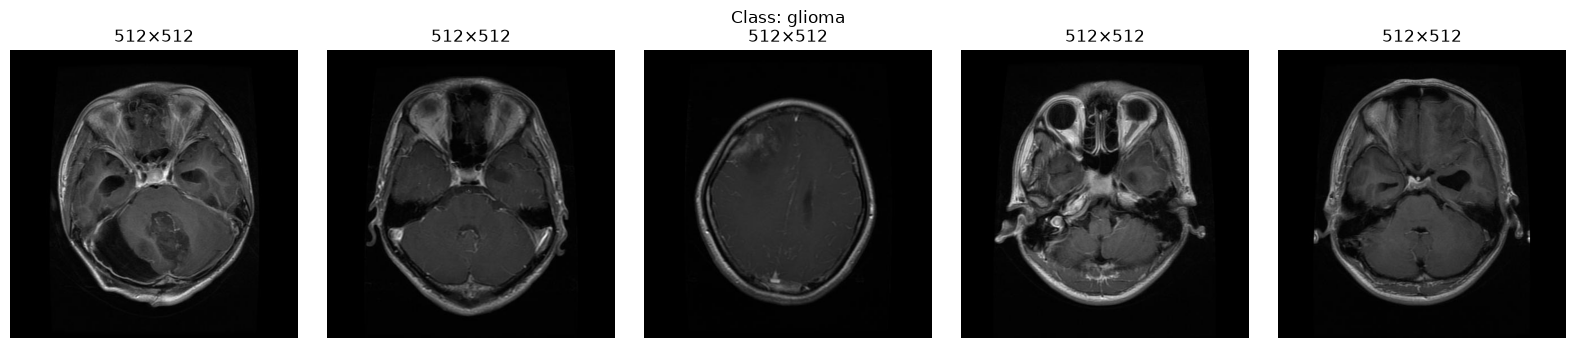

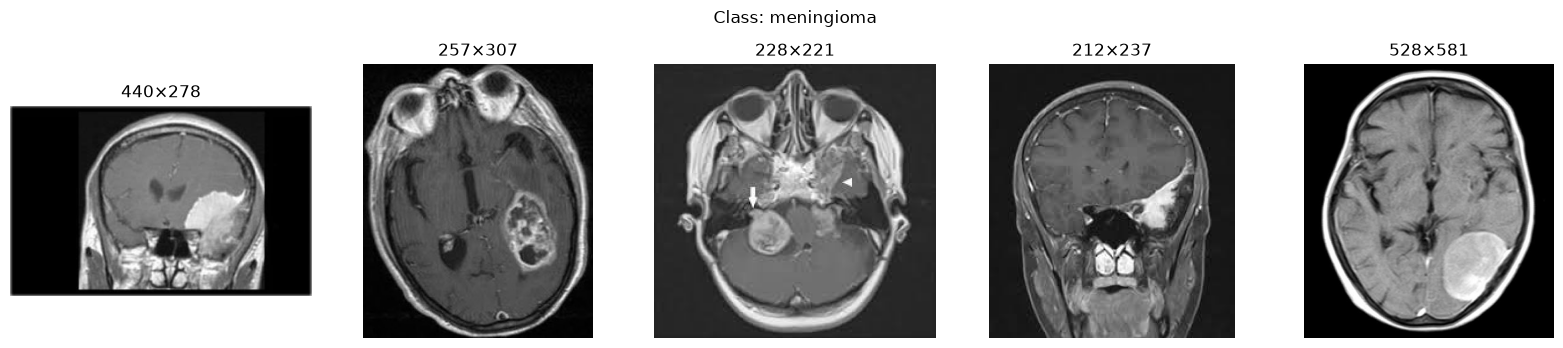

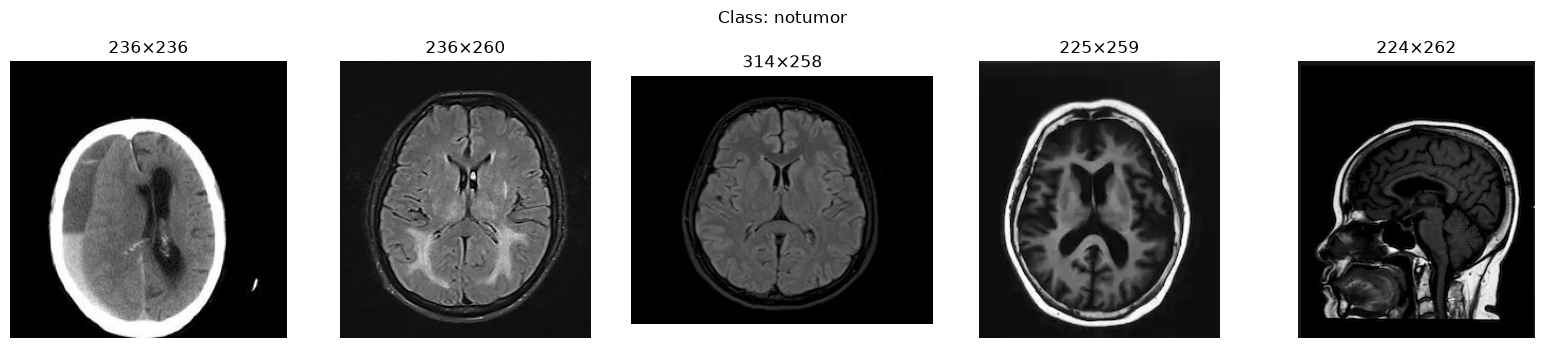

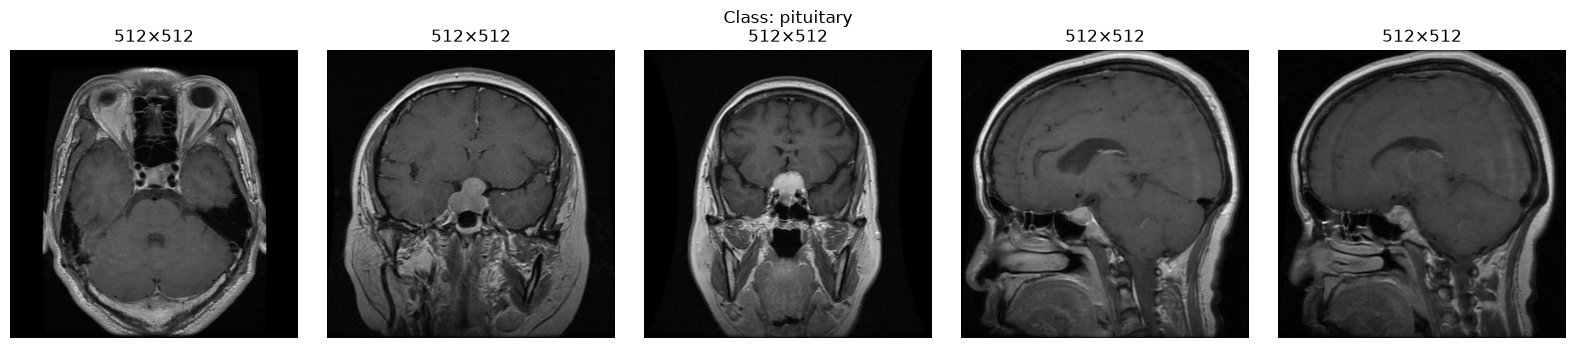

In [7]:
labels = sorted(valid_manifest["label"].unique())
for label in labels:
    sample = valid_manifest[valid_manifest["label"] == label].head(MAX_EXAMPLES_PER_CLASS)
    if sample.empty:
        continue
    n = len(sample)
    fig, axes = plt.subplots(1, n, figsize=(3.2 * n, 3.5), squeeze=False)
    fig.suptitle(f"Class: {label}")
    for ax, (_, row) in zip(axes[0], sample.iterrows()):
        with Image.open(row["image_path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"{row['width']}×{row['height']}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


### 8. Inspect image dimensions and file types

,width,height,image_mode,extension,file_size_bytes
count,7023.000000,7023.000000,7023,7023,7023.000000
unique,NaN,NaN,4,1,NaN
top,NaN,NaN,RGB,.jpg,NaN
freq,NaN,NaN,3926,7023,NaN
mean,445.891499,448.346860,NaN,NaN,22583.582087
std,132.328035,126.282922,NaN,NaN,16214.672232
min,150.000000,168.000000,NaN,NaN,3475.000000
25%,393.000000,403.500000,NaN,NaN,15353.000000
50%,512.000000,512.000000,NaN,NaN,21053.000000
75%,512.000000,512.000000,NaN,NaN,27023.000000


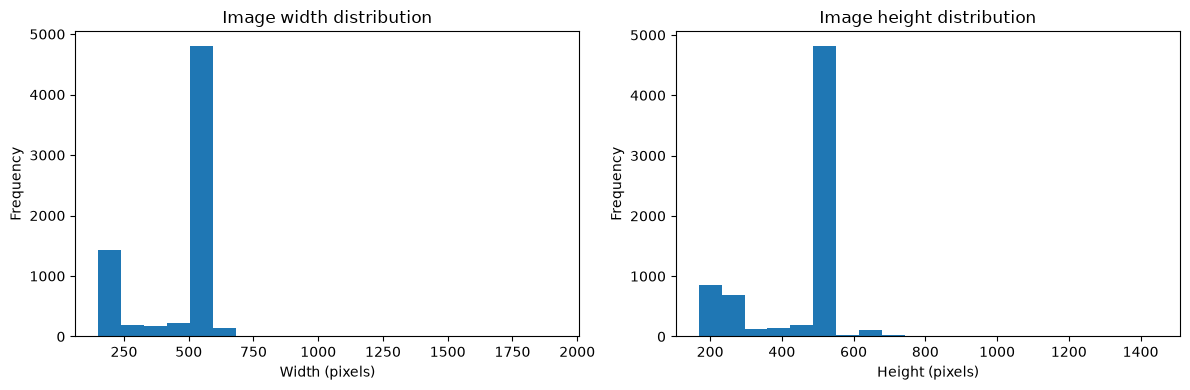

Extensions:


,count
extension,
.jpg,7023


In [8]:
display(valid_manifest[["width", "height", "image_mode", "extension", "file_size_bytes"]].describe(include="all"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
valid_manifest["width"].plot(kind="hist", bins=20, ax=axes[0], title="Image width distribution")
valid_manifest["height"].plot(kind="hist", bins=20, ax=axes[1], title="Image height distribution")
axes[0].set_xlabel("Width (pixels)")
axes[1].set_xlabel("Height (pixels)")
plt.tight_layout()
plt.show()

print("Extensions:")
display(valid_manifest["extension"].value_counts().to_frame("count"))


### 9. Export the manifest and exploration reports
The manifest contains absolute image paths for immediate local use. If you move the project to another machine, prefer relative_path or regenerate the manifest after updating DATASET_ROOT. Patient IDs and bounding-box annotations are not inferred here; add them from the source annotations when available.

In [9]:
manifest_path = PROCESSED_DIR / "manifest.csv"
invalid_path = PROCESSED_DIR / "invalid_images.csv"
summary_path = PROCESSED_DIR / "exploration_summary.json"

# Keep only valid images in the manifest for the next notebook.
columns_for_manifest = [
    "image_path", "relative_path", "label", "extension",
    "file_size_bytes", "width", "height", "image_mode", "is_valid"
]
valid_manifest[columns_for_manifest].to_csv(manifest_path, index=False)

if not invalid_manifest.empty:
    invalid_manifest.to_csv(invalid_path, index=False)

summary = {
    "dataset_root": str(DATASET_ROOT.resolve()),
    "images_discovered": int(len(manifest)),
    "valid_images": int(len(valid_manifest)),
    "invalid_images": int(len(invalid_manifest)),
    "num_classes": int(valid_manifest["label"].nunique()),
    "class_counts": {str(k): int(v) for k, v in valid_manifest["label"].value_counts().items()},
    "extensions": {str(k): int(v) for k, v in valid_manifest["extension"].value_counts().items()},
    "random_seed": SEED,
}
summary_path.write_text(json.dumps(summary, indent=2), encoding="utf-8")

print("Manifest saved:", manifest_path)
print("Summary saved:", summary_path)
if not invalid_manifest.empty:
    print("Invalid-image report saved:", invalid_path)
display(pd.DataFrame([summary]))


Manifest saved: /home/moali/projects/brainscan_ai/data/processed/manifest.csv
Summary saved: /home/moali/projects/brainscan_ai/data/processed/exploration_summary.json


,dataset_root,images_discovered,valid_images,invalid_images,num_classes,class_counts,extensions,random_seed
0,/home/moali/projects/brainscan_ai/data/raw,7023,7023,0,4,"{'notumor': 2000, 'pituitary': 1757, 'meningio...",{'.jpg': 7023},42
